# Problem 4.2: Discrete Latent Diffusion on VQ-VAE Tokens

Each CIFAR-10 image is represented by the 4.1 **VQ-VAE** as **10 × 8 × 8 = 640 codebook indices in {0, ..., 127}**.
We train a diffusion model on these tokens, generate new token grids, and decode them with the VQ-VAE decoder.

**Why masked (absorbing-state) diffusion?** VQ indices are *unordered* labels (index 57 is not "between" 56 and 58),
so adding Gaussian noise to them makes no sense. Discrete diffusion corrupts tokens by **replacing them with a [MASK] token**
(D3PM absorbing state, Austin et al. 2021; MaskGIT, Chang et al. 2022):

| | Gaussian diffusion | Masked discrete diffusion (this notebook) |
|---|---|---|
| Forward (noising) | add Gaussian noise | replace tokens with **[MASK]** |
| Fully noised | pure noise | every token is [MASK] |
| Network learns | predict the noise | predict the original token at every masked position (cross-entropy) |
| Sampling | denoise step by step | **unmask** step by step, most confident tokens first |

**To reach FID < 40** we also use:
- **Class conditioning + classifier-free guidance (CFG)**: the label is dropped 10% of the time; at sampling the
  conditional and unconditional predictions are combined: logits = l_u + w (l_c − l_u).
- **Horizontal-flip augmentation**: flipped images are re-encoded with the VQ-VAE encoder → 100,000 token grids.
- **Automatic stopping**: FID is checked every 15 epochs; training stops once FID < 40, or after **10 hours**
  (Kaggle's limit is 12 h), so the final FID, the images and all files are always produced.
- **Final FID with two protocols**: 10,000 generated vs. the 10,000 test images, and the standard
  50,000 generated vs. the 50,000 training images.

**Inputs (from the 4.1 notebook):** `vqvae.pt`, `vq_tokens.pt` and `cifar10_uint8.pt`.

### Running on Kaggle (recommended: runs in the background, laptop can be closed)
1. Open this notebook on Kaggle (*Code → New Notebook → File → Import Notebook*).
2. Right panel → **Add Input** → **Your Work / Notebooks** → pick your **4.1 notebook** → add its **Output**.
   (Or upload the three files as a dataset.) The files are found automatically anywhere under `/kaggle/input`.
3. Settings: **Accelerator → GPU** (T4 x2 or P100), **Internet → On**.
4. **Save Version → Save & Run All (Commit)**. Results appear in the version's **Output** tab.
5. If it stops (12-hour limit), add this notebook's previous **Output** as an input too and commit again: it resumes
   from `vqdiff_ckpt.pt`.

**Colab** also works (`MyDrive/mm811_p4_simple`), but the tab must stay open the whole time.

## 1. Settings and storage

In [1]:
import os, glob, math, time, copy, shutil
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

NOTEBOOK_START = time.time()
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

# VQ-VAE settings (must match 4.1)
GROUPS, K, CODE_DIM = 10, 128, 8
MASK = K                 # extra token id 128 = [MASK]
NUM_CLASSES = 10         # label 10 = "no label" (for CFG)

# diffusion model / training
DIM, DEPTH, HEADS = 512, 12, 8
BATCH_SIZE = 256
LR = 3e-4
MAX_EPOCHS = 300         # upper limit; usually stops earlier
TRAIN_HOURS = 10.0       # stop training after this (Kaggle limit is 12 h; ~1 h is needed for the final FID)
CHECK_EVERY = 15         # quick FID every 15 epochs; stop when below the target
TARGET_FID = 40
P_UNCOND = 0.1
EMA_DECAY = 0.999
SAMPLE_STEPS = 32        # unmasking steps when generating
print("device:", device)

ON_KAGGLE = os.path.exists("/kaggle")
if ON_KAGGLE:
    SAVE_DIR = "/kaggle/working"
else:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/mm811_p4_simple"
os.makedirs(SAVE_DIR, exist_ok=True)


def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) if ON_KAGGLE else []
    for p in [f"{SAVE_DIR}/{name}"] + hits:
        if os.path.exists(p):
            return p
    return None


if ON_KAGGLE:   # copy inputs (and a previous run's checkpoint, to resume) into the working folder
    for name in ["vqvae.pt", "vq_tokens.pt", "cifar10_uint8.pt", "vqdiff_ckpt.pt", "vqdiff_best.pt"]:
        p = find(name)
        if p and not os.path.exists(f"{SAVE_DIR}/{name}"):
            shutil.copy(p, SAVE_DIR); print("found", p)
assert find("vqvae.pt") and find("vq_tokens.pt"), "vqvae.pt / vq_tokens.pt not found: run the 4.1 notebook first"
print("files:", sorted(os.listdir(SAVE_DIR)))

device: cuda
found /kaggle/input/notebooks/rachdewanjee/notebooka5bf4cb3eb/vqvae.pt
found /kaggle/input/notebooks/rachdewanjee/notebooka5bf4cb3eb/vq_tokens.pt
found /kaggle/input/notebooks/rachdewanjee/notebook72fb9fed72/cifar10_uint8.pt
files: ['__notebook__.ipynb', 'cifar10_uint8.pt', 'vq_tokens.pt', 'vqvae.pt']


## 2. CIFAR-10 (labels for conditioning, training images for flips, test images for FID)

In [2]:
cache = find("cifar10_uint8.pt")
if cache:
    cifar = torch.load(cache)
    print("loaded CIFAR-10 from", cache)
else:
    from torchvision import datasets
    tr = datasets.CIFAR10("./data", train=True, download=True)
    te = datasets.CIFAR10("./data", train=False, download=True)
    cifar = {"train_x": torch.from_numpy(tr.data).permute(0, 3, 1, 2).contiguous(), "train_y": torch.tensor(tr.targets),
             "test_x": torch.from_numpy(te.data).permute(0, 3, 1, 2).contiguous(), "test_y": torch.tensor(te.targets)}
    torch.save(cifar, f"{SAVE_DIR}/cifar10_uint8.pt")
    print("downloaded CIFAR-10 and saved cifar10_uint8.pt")
to_float = lambda x: x.to(device).float().div(255)

loaded CIFAR-10 from /kaggle/working/cifar10_uint8.pt


## 3. Load the 4.1 VQ-VAE
Same classes as in 4.1 so the saved weights load exactly. The encoder makes tokens (for flipped images), the decoder turns
generated tokens back into images.

In [3]:
def block(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU())


class GroupedVQ(nn.Module):
    def __init__(self, groups, k, dim, decay=0.99, eps=1e-5):
        super().__init__()
        self.G, self.K, self.d = groups, k, dim
        self.register_buffer("embed", torch.randn(groups, k, dim))
        self.register_buffer("embed_avg", self.embed.clone())
        self.register_buffer("cluster_size", torch.ones(groups, k))
        self.register_buffer("initted", torch.tensor(False))

    def forward(self, z):     # inference only here: nearest code per group
        B, _, H, W = z.shape
        z = z.float().view(B, self.G, self.d, H, W).permute(1, 0, 3, 4, 2).reshape(self.G, -1, self.d)
        dist = (z ** 2).sum(-1, keepdim=True) - 2 * z @ self.embed.transpose(1, 2) + (self.embed ** 2).sum(-1)[:, None]
        idx = dist.argmin(-1)
        return idx.view(self.G, B, H, W).permute(1, 0, 2, 3)

    def lookup(self, idx):
        B, G, H, W = idx.shape
        q = torch.stack([self.embed[g][idx[:, g]] for g in range(G)], 1)
        return q.permute(0, 1, 4, 2, 3).reshape(B, G * self.d, H, W)


class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.net = nn.Sequential(nn.ReLU(), nn.Conv2d(c, c, 3, padding=1), nn.BatchNorm2d(c),
                                 nn.ReLU(), nn.Conv2d(c, c, 1), nn.BatchNorm2d(c))

    def forward(self, x):
        return x + self.net(x)


class VQVAE(nn.Module):
    def __init__(self):
        super().__init__()
        latent = GROUPS * CODE_DIM
        self.encoder = nn.Sequential(
            block(3, 64),
            nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            block(128, 128),
            nn.Conv2d(128, 256, 4, stride=2, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            ResBlock(256), ResBlock(256), nn.ReLU(),
            nn.Conv2d(256, latent, 1),
        )
        self.vq = GroupedVQ(GROUPS, K, CODE_DIM)
        self.decoder = nn.Sequential(
            nn.Conv2d(latent, 256, 3, padding=1), nn.BatchNorm2d(256),
            ResBlock(256), ResBlock(256), nn.ReLU(),
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            block(128, 128),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 3, 3, padding=1),
            nn.Sigmoid(),
        )


vq = VQVAE().to(device)
vq.load_state_dict(torch.load(find("vqvae.pt"), map_location=device))
vq.eval()


@torch.no_grad()
def encode(imgs_uint8):
    return torch.cat([vq.vq(vq.encoder(to_float(imgs_uint8[i:i + 500]))).cpu() for i in range(0, len(imgs_uint8), 500)])


@torch.no_grad()
def decode(tok):
    return torch.cat([vq.decoder(vq.vq.lookup(tok[i:i + 500].long().to(device))).cpu() for i in range(0, len(tok), 500)])


def show_grid(images, title, path=None, nrow=8):
    rows = math.ceil(len(images) / nrow)
    fig, axes = plt.subplots(rows, nrow, figsize=(nrow * 1.3, rows * 1.3))
    for ax in axes.flat:
        ax.axis("off")
    for i, img in enumerate(images):
        axes.flat[i].imshow(img.permute(1, 2, 0).clamp(0, 1))
    fig.suptitle(title); plt.tight_layout()
    if path:
        plt.savefig(path, dpi=120)
    plt.show()

## 4. Tokens: originals + horizontally flipped

re-encoded vs saved tokens: 100.00% identical
training token grids: 100000 (originals + flips)


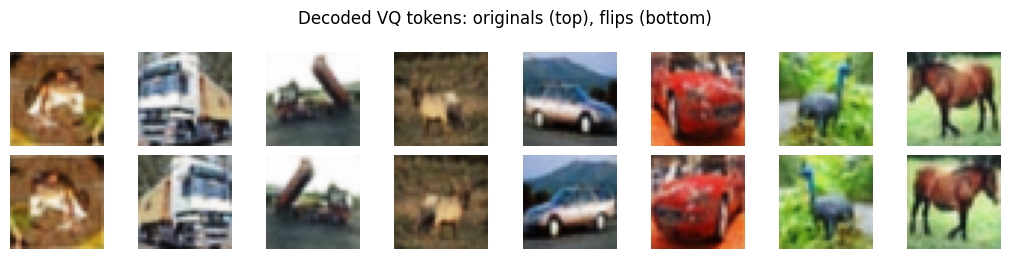

In [4]:
saved = torch.load(find("vq_tokens.pt"))
assert saved["codebook_size"] == K
train_tok, test_tok = saved["train"].long(), saved["test"].long()          # (50000, 10, 8, 8), values 0..127
train_y, test_y = cifar["train_y"], cifar["test_y"]

check = encode(cifar["train_x"][:1000])
print(f"re-encoded vs saved tokens: {100 * (check == train_tok[:1000]).float().mean():.2f}% identical")

flip_tok = encode(cifar["train_x"].flip(-1))
x_train = torch.cat([train_tok, flip_tok])
y_train = torch.cat([train_y, train_y])
train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
print("training token grids:", len(x_train), "(originals + flips)")
show_grid(torch.cat([decode(train_tok[:8]), decode(flip_tok[:8])]), "Decoded VQ tokens: originals (top), flips (bottom)")

## 5. Denoising network (class-conditional Transformer)
The 8 × 8 grid is treated as **64 positions**. At each position there are 10 tokens (one per codebook); each token
(0..127 or [MASK]) has an embedding, and the 10 embeddings are **added**. A position embedding, the mask ratio t and the
class label are added too. The output at each position is **10 × 128 logits**: a prediction for each of the 10 tokens.

In [5]:
class Denoiser(nn.Module):
    def __init__(self, dim=DIM, depth=DEPTH, heads=HEADS):
        super().__init__()
        self.tok_emb = nn.Embedding(GROUPS * (K + 1), dim)         # separate table per codebook
        self.pos_emb = nn.Parameter(torch.zeros(1, 64, dim))
        self.time_mlp = nn.Sequential(nn.Linear(1, dim), nn.SiLU(), nn.Linear(dim, dim))
        self.label_emb = nn.Embedding(NUM_CLASSES + 1, dim)
        layer = nn.TransformerEncoderLayer(dim, heads, 4 * dim, dropout=0.1, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, GROUPS * K)
        nn.init.normal_(self.pos_emb, std=0.02)
        self.register_buffer("offset", torch.arange(GROUPS) * (K + 1))

    def forward(self, x, t, y):
        # x: (B, 10, 8, 8) values 0..128 (128 = MASK); t: (B,) mask ratio; y: (B,) labels 0..10
        B = x.shape[0]
        h = self.tok_emb(x.flatten(2).transpose(1, 2) + self.offset).sum(2)        # (B, 64, dim)
        h = h + self.pos_emb + (self.time_mlp(t.view(B, 1)) + self.label_emb(y))[:, None]
        h = self.norm(self.transformer(h))
        logits = self.head(h).view(B, 64, GROUPS, K)
        return logits.permute(0, 3, 2, 1).reshape(B, K, GROUPS, 8, 8)              # (B, 128, 10, 8, 8)


model = Denoiser().to(device)
ema = copy.deepcopy(model).eval().requires_grad_(False)
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 39448832


## 6. Forward process (masking) and training loss
For each training grid: draw u ~ U(0, 1), set the **mask ratio** t = cos(π u / 2) (cosine schedule, more weight on
heavily-masked inputs), mask each of the 640 tokens with probability t, and train with **cross-entropy on the masked tokens**.
The label is replaced by "no label" 10% of the time (for CFG).

In [6]:
def mask_ratio(u):
    return torch.cos(math.pi / 2 * u)


def loss_fn(net, x, y):
    B = x.shape[0]
    t = mask_ratio(torch.rand(B, device=x.device)).clamp(min=1 / 640)
    masked = torch.rand(x.shape, device=x.device) < t.view(B, 1, 1, 1)
    x_in = torch.where(masked, torch.full_like(x, MASK), x)
    y = torch.where(torch.rand(B, device=y.device) < P_UNCOND, torch.full_like(y, NUM_CLASSES), y)
    with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
        logits = net(x_in, t, y)
    ce = F.cross_entropy(logits.float(), x, reduction="none")                     # (B, 10, 8, 8)
    return (ce * masked).sum() / masked.sum().clamp(min=1)


@torch.no_grad()
def test_loss(net, n=2000):
    net.eval()
    n = min(n, len(test_tok))
    g = torch.Generator(device=device).manual_seed(0)
    x, y = test_tok[:n].to(device), test_y[:n].to(device)
    t = mask_ratio(torch.rand(n, device=device, generator=g)).clamp(min=1 / 640)
    masked = torch.rand(x.shape, device=device, generator=g) < t.view(n, 1, 1, 1)
    logits = net(torch.where(masked, torch.full_like(x, MASK), x), t, y)
    return ((F.cross_entropy(logits, x, reduction="none") * masked).sum() / masked.sum()).item()

## 7. Sampler: iterative unmasking with classifier-free guidance
Start with all 640 tokens = [MASK]. At step s of S:
1. Run the network with the label and without it; guided logits = l_u + w · (l_c − l_u).
2. Sample a token for every masked position from softmax(logits).
3. Keep masked only the n_s = ⌊640 · cos(π/2 · s/S)⌋ **least confident** positions (confidence = log-probability of the
   sampled token, plus a little random noise early on for diversity); all others become fixed.

After the last step every token is fixed. The token grid is then decoded with the VQ-VAE decoder.

In [7]:
@torch.no_grad()
def sample(net, labels, steps=SAMPLE_STEPS, w=2.0, temperature=1.0, noise=2.0):
    net.eval()
    n = len(labels)
    y = labels.to(device)
    y_null = torch.full_like(y, NUM_CLASSES)
    x = torch.full((n, GROUPS, 8, 8), MASK, device=device)
    N = GROUPS * 64
    for s in range(1, steps + 1):
        is_masked = x == MASK
        t = is_masked.float().flatten(1).mean(1)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            lc, lu = net(torch.cat([x, x]), torch.cat([t, t]), torch.cat([y, y_null])).float().chunk(2)
        logits = (lu + w * (lc - lu)) / temperature                                   # (n, 128, 10, 8, 8)
        logp = F.log_softmax(logits, dim=1)
        guess = torch.distributions.Categorical(logits=logits.permute(0, 2, 3, 4, 1)).sample()   # (n, 10, 8, 8)
        conf = torch.gather(logp, 1, guess[:, None]).squeeze(1)
        gumbel = -torch.log(-torch.log(torch.rand_like(conf).clamp(1e-9, 1 - 1e-9)))
        conf = conf + noise * (1 - s / steps) * gumbel
        conf = torch.where(is_masked, conf, torch.full_like(conf, float("inf")))        # fixed tokens stay fixed
        x = torch.where(is_masked, guess, x)
        n_keep_masked = int(N * math.cos(math.pi / 2 * s / steps))
        if n_keep_masked > 0:
            lowest = conf.flatten(1).topk(n_keep_masked, dim=1, largest=False).indices
            x = x.flatten(1).scatter(1, lowest, MASK).view_as(x)
    assert (x != MASK).all()
    return x.cpu()


def balanced_labels(n):
    return torch.arange(n) % NUM_CLASSES

## 8. FID setup

In [8]:
!pip -q install torchmetrics[image]
from torchmetrics.image.fid import FrechetInceptionDistance

to_uint8 = lambda imgs: (imgs.clamp(0, 1) * 255).to(torch.uint8)
fid = FrechetInceptionDistance(feature=2048, reset_real_features=False).to(device)
for i in range(0, 10000, 500):
    fid.update(cifar["test_x"][i:i + 500].to(device), real=True)


def fid_of(fake_imgs):
    fid.reset()
    for i in range(0, len(fake_imgs), 500):
        fid.update(to_uint8(fake_imgs[i:i + 500]).to(device), real=False)
    return fid.compute().item()


def fid_of_model(net, n, w, seed=3):
    torch.manual_seed(seed)
    labels = balanced_labels(n)
    tok = torch.cat([sample(net, labels[i:i + 500], w=w) for i in range(0, n, 500)])
    return fid_of(decode(tok))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.6/85.6 kB 2.8 MB/s eta 0:00:00


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 315MB/s]


## 9. Training (stops at FID < 40, or after 10 hours)
Every 15 epochs: quick FID on 5,000 images with guidance w = 1.5, 2 and 3. A 5,000-image FID is slightly *higher* than the
final 10,000-image one, so stopping on it is safe. The best model is saved as `vqdiff_best.pt`; a checkpoint is saved every
epoch (`vqdiff_ckpt.pt`), so re-running continues where it stopped.

Epoch   1 | train loss 4.7016 | test loss (EMA) 4.8434 | 192s | 0.07 h total
Epoch   2 | train loss 4.4688 | test loss (EMA) 4.6834 | 192s | 0.13 h total
Epoch   3 | train loss 4.3312 | test loss (EMA) 4.5971 | 193s | 0.18 h total
Epoch   4 | train loss 4.2375 | test loss (EMA) 4.4966 | 193s | 0.23 h total
Epoch   5 | train loss 4.1578 | test loss (EMA) 4.3773 | 193s | 0.29 h total
Epoch   6 | train loss 4.1017 | test loss (EMA) 4.2643 | 193s | 0.34 h total
Epoch   7 | train loss 4.0560 | test loss (EMA) 4.1732 | 193s | 0.40 h total
Epoch   8 | train loss 4.0257 | test loss (EMA) 4.1043 | 193s | 0.45 h total
Epoch   9 | train loss 3.9998 | test loss (EMA) 4.0516 | 193s | 0.50 h total
Epoch  10 | train loss 3.9799 | test loss (EMA) 4.0106 | 193s | 0.56 h total
Epoch  11 | train loss 3.9584 | test loss (EMA) 3.9777 | 194s | 0.61 h total
Epoch  12 | train loss 3.9227 | test loss (EMA) 3.9495 | 193s | 0.67 h total
Epoch  13 | train loss 3.8943 | test loss (EMA) 3.9212 | 193s | 0.72 h total

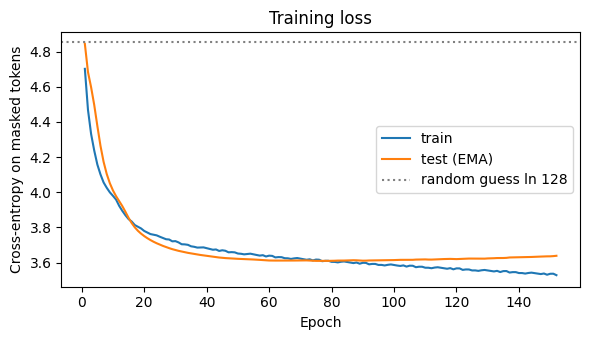

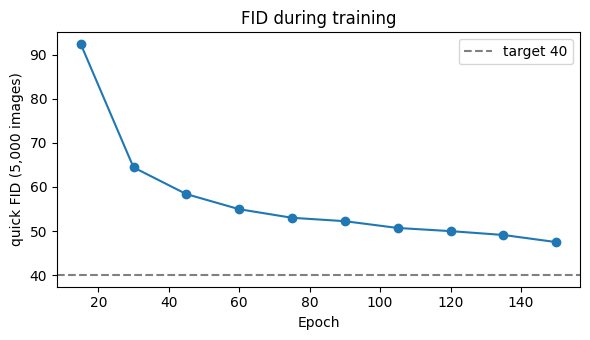

In [9]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = MAX_EPOCHS * len(train_loader)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer, lambda s: min(1.0, (s + 1) / 1000) * max(0.1, 0.5 * (1 + math.cos(math.pi * s / total_steps))))
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

CKPT, BEST = f"{SAVE_DIR}/vqdiff_ckpt.pt", f"{SAVE_DIR}/vqdiff_best.pt"
start_epoch, train_losses, test_losses, checks = 1, [], [], []
best_fid, best_w = float("inf"), 2.0
if os.path.exists(CKPT):
    ck = torch.load(CKPT, map_location=device)
    model.load_state_dict(ck["model"]); ema.load_state_dict(ck["ema"])
    optimizer.load_state_dict(ck["opt"]); scheduler.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start_epoch, train_losses, test_losses = ck["epoch"] + 1, ck["train_losses"], ck["test_losses"]
    checks, best_fid, best_w = ck["checks"], ck["best_fid"], ck["best_w"]
    print(f"resuming from epoch {start_epoch} | best quick FID so far {best_fid:.1f}")

done = best_fid < TARGET_FID
for epoch in range(start_epoch, MAX_EPOCHS + 1):
    hours = (time.time() - NOTEBOOK_START) / 3600
    if done or hours > TRAIN_HOURS:
        if not done:
            print(f"time budget reached ({hours:.1f} h) -> stopping training")
        break
    model.train()
    running, t0 = 0.0, time.time()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model, x, y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        with torch.no_grad():
            for pe, pm in zip(ema.parameters(), model.parameters()):
                pe.lerp_(pm, 1 - EMA_DECAY)
        running += loss.item()

    train_losses.append(running / len(train_loader))
    test_losses.append(test_loss(ema))
    print(f"Epoch {epoch:3d} | train loss {train_losses[-1]:.4f} | test loss (EMA) {test_losses[-1]:.4f} "
          f"| {time.time() - t0:.0f}s | {(time.time() - NOTEBOOK_START) / 3600:.2f} h total")

    if epoch % CHECK_EVERY == 0 or epoch == MAX_EPOCHS:
        t1 = time.time()
        scores = {w: fid_of_model(ema, 5000, w) for w in [1.5, 2.0, 3.0]}
        w_best = min(scores, key=scores.get)
        checks.append((epoch, scores[w_best], w_best))
        print(f"   quick FID @ epoch {epoch}: " + ", ".join(f"w={w}: {v:.1f}" for w, v in scores.items())
              + f"  ({time.time() - t1:.0f}s)")
        if scores[w_best] < best_fid:
            best_fid, best_w = scores[w_best], w_best
            torch.save({"ema": ema.state_dict(), "w": best_w, "epoch": epoch, "quick_fid": best_fid}, BEST)
            print(f"   new best model saved (quick FID {best_fid:.1f}, w = {best_w})")
        if best_fid < TARGET_FID:
            print(f"   TARGET REACHED: quick FID {best_fid:.1f} < {TARGET_FID} -> stopping training")
            done = True

    torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "opt": optimizer.state_dict(),
                "sched": scheduler.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch,
                "train_losses": train_losses, "test_losses": test_losses,
                "checks": checks, "best_fid": best_fid, "best_w": best_w}, CKPT)

if os.path.exists(BEST):
    best = torch.load(BEST, map_location=device)
    ema.load_state_dict(best["ema"]); best_w = best["w"]
    print(f"Using best model: epoch {best['epoch']}, quick FID {best['quick_fid']:.1f}, w = {best_w}")

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(train_losses) + 1), train_losses, label="train")
plt.plot(range(1, len(test_losses) + 1), test_losses, label="test (EMA)")
plt.axhline(math.log(K), color="gray", linestyle=":", label=f"random guess ln {K}")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy on masked tokens"); plt.title("Training loss")
plt.legend(); plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/vqdiff_loss.png", dpi=120); plt.show()
if checks:
    plt.figure(figsize=(6, 3.5))
    plt.plot([c[0] for c in checks], [c[1] for c in checks], "o-")
    plt.axhline(TARGET_FID, color="gray", linestyle="--", label="target 40")
    plt.xlabel("Epoch"); plt.ylabel("quick FID (5,000 images)"); plt.title("FID during training")
    plt.legend(); plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/vqdiff_fid_curve.png", dpi=120); plt.show()

## 10. Generated images (one row per class) and the reverse process

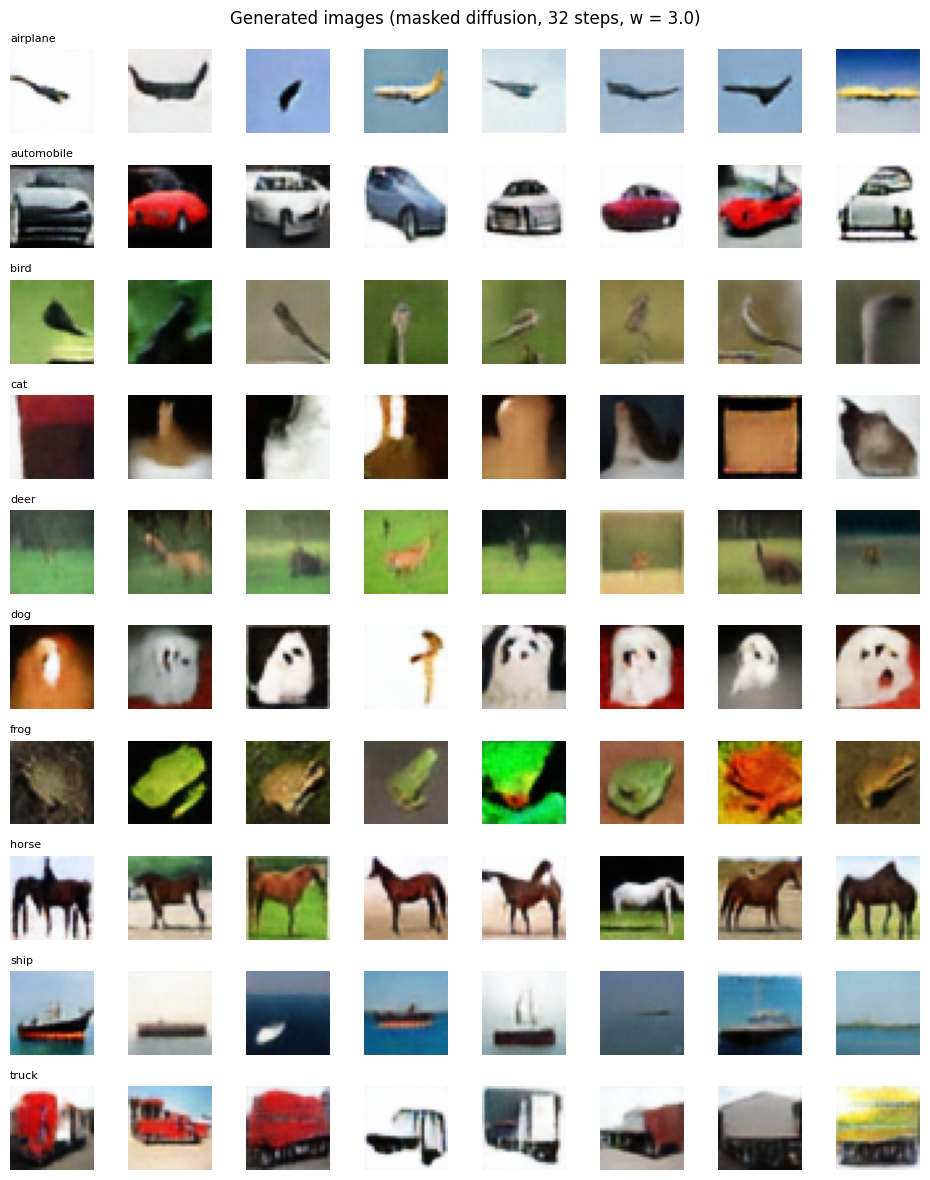

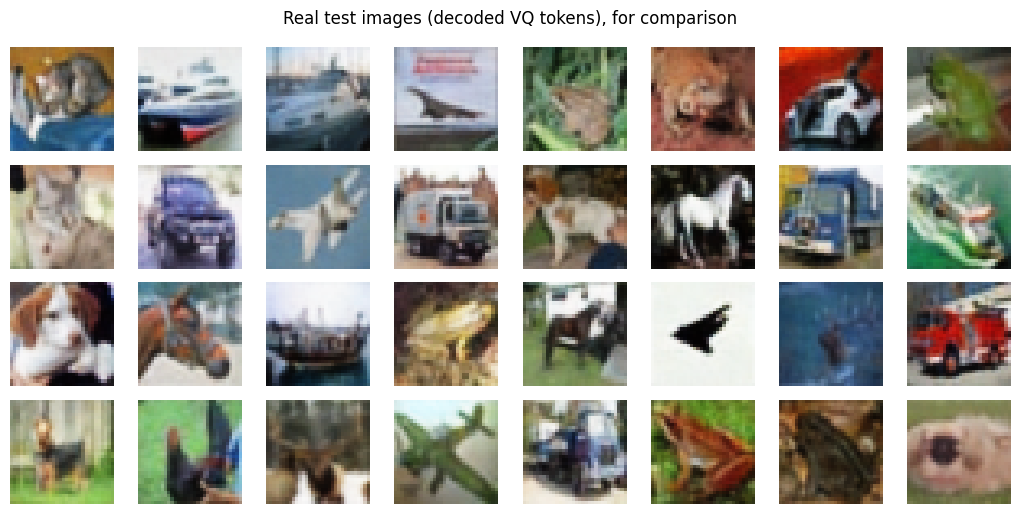

In [10]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
torch.manual_seed(0)
labels = torch.arange(NUM_CLASSES).repeat_interleave(8)
imgs = decode(sample(ema, labels, w=best_w))
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(8 * 1.2, NUM_CLASSES * 1.2))
for i in range(NUM_CLASSES * 8):
    ax = axes[i // 8, i % 8]
    ax.imshow(imgs[i].permute(1, 2, 0).clamp(0, 1)); ax.axis("off")
    if i % 8 == 0:
        ax.set_title(CLASSES[i // 8], loc="left", fontsize=8)
plt.suptitle(f"Generated images (masked diffusion, {SAMPLE_STEPS} steps, w = {best_w})")
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/vqdiff_samples.png", dpi=120); plt.show()

show_grid(decode(test_tok[:32]), "Real test images (decoded VQ tokens), for comparison", f"{SAVE_DIR}/vq_real_decoded.png")

## 11. Final FID (target < 40)
10,000 generated images (1,000 per class) against the 10,000 real CIFAR-10 test images, using the best model,
and the standard protocol: 50,000 generated images (5,000 per class) against the 50,000 CIFAR-10 training images.
The first line scores the VQ-VAE's own reconstructions: the best FID any model can reach with this decoder.

In [11]:
import json
N_FID = 10000
results = {"VQ-VAE recon (best possible)": fid_of(decode(test_tok[:N_FID]))}
for w in sorted({1.5, best_w, 3.0}):
    t0 = time.time()
    results[f"{SAMPLE_STEPS} steps, w = {w}"] = fid_of_model(ema, N_FID, w)
    print(f"w = {w}: FID {results[f'{SAMPLE_STEPS} steps, w = {w}']:.1f}  ({time.time() - t0:.0f}s)")

best_name = min((k for k in results if not k.startswith("VQ-VAE")), key=results.get)
w_final = float(best_name.split("w = ")[1])
with open(f"{SAVE_DIR}/vqdiff_fid_results.json", "w") as f:
    json.dump(results, f, indent=2)

# standard protocol: 50,000 generated images (5,000 per class) vs. the 50,000 CIFAR-10 training images
t0 = time.time()
torch.manual_seed(0)
labels50 = balanced_labels(50000)
tok50 = torch.cat([sample(ema, labels50[i:i + 500], w=w_final) for i in range(0, 50000, 500)])
fake50 = decode(tok50)
fid_train = FrechetInceptionDistance(feature=2048).to(device)
for i in range(0, 50000, 500):
    fid_train.update(cifar["train_x"][i:i + 500].to(device), real=True)
    fid_train.update(to_uint8(fake50[i:i + 500]).to(device), real=False)
results[f"50k vs 50k train, w = {w_final}"] = fid_train.compute().item()
print(f"50k vs 50k train, w = {w_final}: FID {results[f'50k vs 50k train, w = {w_final}']:.1f}  "
      f"({(time.time() - t0) / 60:.0f} min)")
with open(f"{SAVE_DIR}/vqdiff_fid_results.json", "w") as f:
    json.dump(results, f, indent=2)

print()
for k, v in results.items():
    print(f"{k:<34}{v:6.1f}   {'< 40 MET' if v < 40 else '>= 40 NOT MET'}")
print(f"\nBest (10k vs test): {best_name}, FID {results[best_name]:.1f}")
print(f"Standard (50k vs train): FID {results[f'50k vs 50k train, w = {w_final}']:.1f} -> target < 40:",
      "MET" if results[f"50k vs 50k train, w = {w_final}"] < 40 else "NOT MET")

w = 1.5: FID 51.6  (436s)
w = 3.0: FID 44.9  (436s)
50k vs 50k train, w = 3.0: FID 41.2  (40 min)

VQ-VAE recon (best possible)         8.0   < 40 MET
32 steps, w = 1.5                   51.6   >= 40 NOT MET
32 steps, w = 3.0                   44.9   >= 40 NOT MET
50k vs 50k train, w = 3.0           41.2   >= 40 NOT MET

Best (10k vs test): 32 steps, w = 3.0, FID 44.9
Standard (50k vs train): FID 41.2 -> target < 40: NOT MET


## 12. Summary

In [12]:
print("Latents:         VQ-VAE (4.1), 10 x 8 x 8 = 640 codebook indices in 0..127")
print("Training data:   50,000 CIFAR-10 training images + horizontal flips = 100,000 token grids")
print("Diffusion:       masked (absorbing-state) discrete diffusion, cosine mask schedule, cross-entropy loss")
print(f"Conditioning:    CIFAR-10 class label, dropped {int(100 * P_UNCOND)}% of the time (classifier-free guidance)")
print(f"Sampler:         iterative confidence-based unmasking, {SAMPLE_STEPS} steps, guidance w = {best_w}")
print(f"Network:         Transformer, {DEPTH} layers, width {DIM}, {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")
print(f"Training:        {len(train_losses)} epochs, {(time.time() - NOTEBOOK_START) / 3600:.1f} h total run time")
print(f"Final test loss: {test_losses[-1]:.3f} (cross-entropy on masked tokens; random guess = {math.log(K):.2f})")
print("FID (10k = 10,000 samples vs test set; 50k = 50,000 samples vs training set):")
for k, v in results.items():
    print(f"   {k:<32}{v:6.1f}")
k50 = [k for k in results if k.startswith('50k')][0]
print(f"Target FID < 40: 10k protocol {'MET' if results[best_name] < 40 else 'NOT MET'} ({results[best_name]:.1f}), "
      f"standard 50k protocol {'MET' if results[k50] < 40 else 'NOT MET'} ({results[k50]:.1f})")

Latents:         VQ-VAE (4.1), 10 x 8 x 8 = 640 codebook indices in 0..127
Training data:   50,000 CIFAR-10 training images + horizontal flips = 100,000 token grids
Diffusion:       masked (absorbing-state) discrete diffusion, cosine mask schedule, cross-entropy loss
Conditioning:    CIFAR-10 class label, dropped 10% of the time (classifier-free guidance)
Sampler:         iterative confidence-based unmasking, 32 steps, guidance w = 3.0
Network:         Transformer, 12 layers, width 512, 39.4M parameters
Training:        152 epochs, 11.0 h total run time
Final test loss: 3.639 (cross-entropy on masked tokens; random guess = 4.85)
FID (10k = 10,000 samples vs test set; 50k = 50,000 samples vs training set):
   VQ-VAE recon (best possible)       8.0
   32 steps, w = 1.5                 51.6
   32 steps, w = 3.0                 44.9
   50k vs 50k train, w = 3.0         41.2
Target FID < 40: 10k protocol NOT MET (44.9), standard 50k protocol NOT MET (41.2)
